What are the most demanded skills for the top 3 most popular data roles?
 
 Methodology
 1. Clean-up skills column
 2. Calculate skill count based on 'job_title_short'
 3. Calculate skill percentage
 4. Plot final findings

In [2]:
# importing Librarires
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from datasets import load_dataset


#loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

c:\Users\Dell\anaconda3\envs\Best_Room\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
df_US = df[df['job_country'] == 'United States']

In [4]:
df_skills = df_US.explode('job_skills')

In [5]:
df_skills_count = df_skills.groupby(['job_skills', 'job_title_short']).size()

df_skills_count = df_skills_count.reset_index(name= 'skill_count')

df_skills_count.sort_values(by= 'skill_count', ascending=False, inplace=True)

C:\Users\Dell\AppData\Local\Temp\ipykernel_18296\2276441729.py:5: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_skills_count.sort_values(by= 'skill_count', ascending=False, inplace=True)


In [6]:
job_titles = ['Data Analyst', 'Data Engineer', 'Data Scientist']

In [7]:
job_titles = df_skills_count['job_title_short'].unique().tolist()

job_titles = sorted(job_titles[:3])

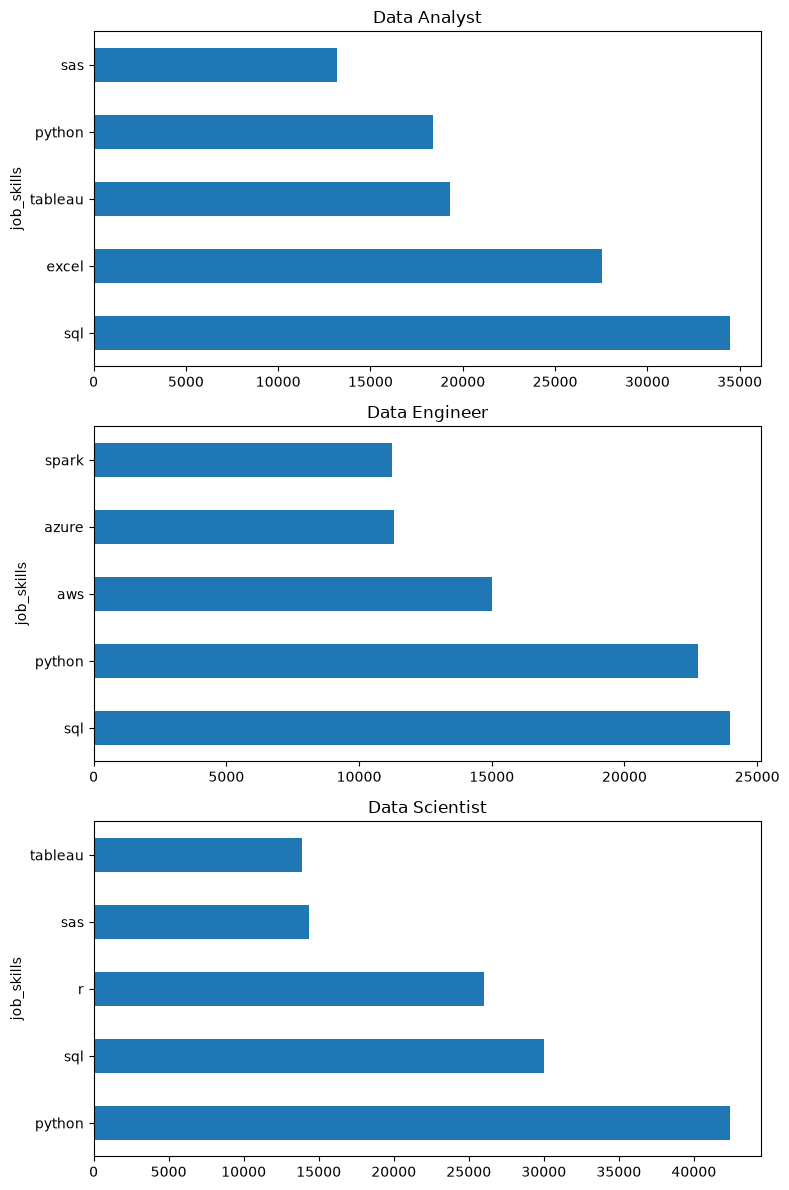

In [8]:
fig, ax = plt.subplots(len(job_titles), 1)
fig.set_size_inches(8, 12)

for i, job_title in enumerate(job_titles):
    df_plot = df_skills_count[
        df_skills_count['job_title_short'] == job_title
    ].head(5)

    df_plot.plot(
        kind='barh',
        x='job_skills',
        y='skill_count',
        ax=ax[i],
        title=job_title,
        legend=False
    )

plt.tight_layout()
plt.show()

In [9]:
df_job_title_count = df_US['job_title_short'].value_counts().reset_index(name= 'job_total')
df_job_title_count

,job_title_short,job_total
0,Data Analyst,67816
1,Data Scientist,58830
2,Data Engineer,35080
3,Senior Data Scientist,12946
4,Senior Data Analyst,11791
5,Senior Data Engineer,9289
6,Business Analyst,7382
7,Software Engineer,1814
8,Machine Learning Engineer,921
9,Cloud Engineer,423


In [10]:
df_skills_count

,job_skills,job_title_short,skill_count
1209,python,Data Scientist,42379
1521,sql,Data Analyst,34452
1523,sql,Data Scientist,30034
455,excel,Data Analyst,27519
1243,r,Data Scientist,26022
...,...,...,...
1785,vue.js,Business Analyst,1
60,arch,Business Analyst,1
71,asana,Machine Learning Engineer,1
968,no-sql,Machine Learning Engineer,1


In [11]:
df_skills_perc = pd.merge(df_skills_count, df_job_title_count, how= 'left', on= 'job_title_short')

df_skills_perc['skill_percent'] = 100 * df_skills_perc['skill_count'] / df_skills_perc['job_total']

df_skills_perc

,job_skills,job_title_short,skill_count,job_total,skill_percent
0,python,Data Scientist,42379,58830,72.036376
1,sql,Data Analyst,34452,67816,50.802171
2,sql,Data Scientist,30034,58830,51.052184
3,excel,Data Analyst,27519,67816,40.578919
4,r,Data Scientist,26022,58830,44.232534
...,...,...,...,...,...
1865,vue.js,Business Analyst,1,7382,0.013546
1866,arch,Business Analyst,1,7382,0.013546
1867,asana,Machine Learning Engineer,1,921,0.108578
1868,no-sql,Machine Learning Engineer,1,921,0.108578


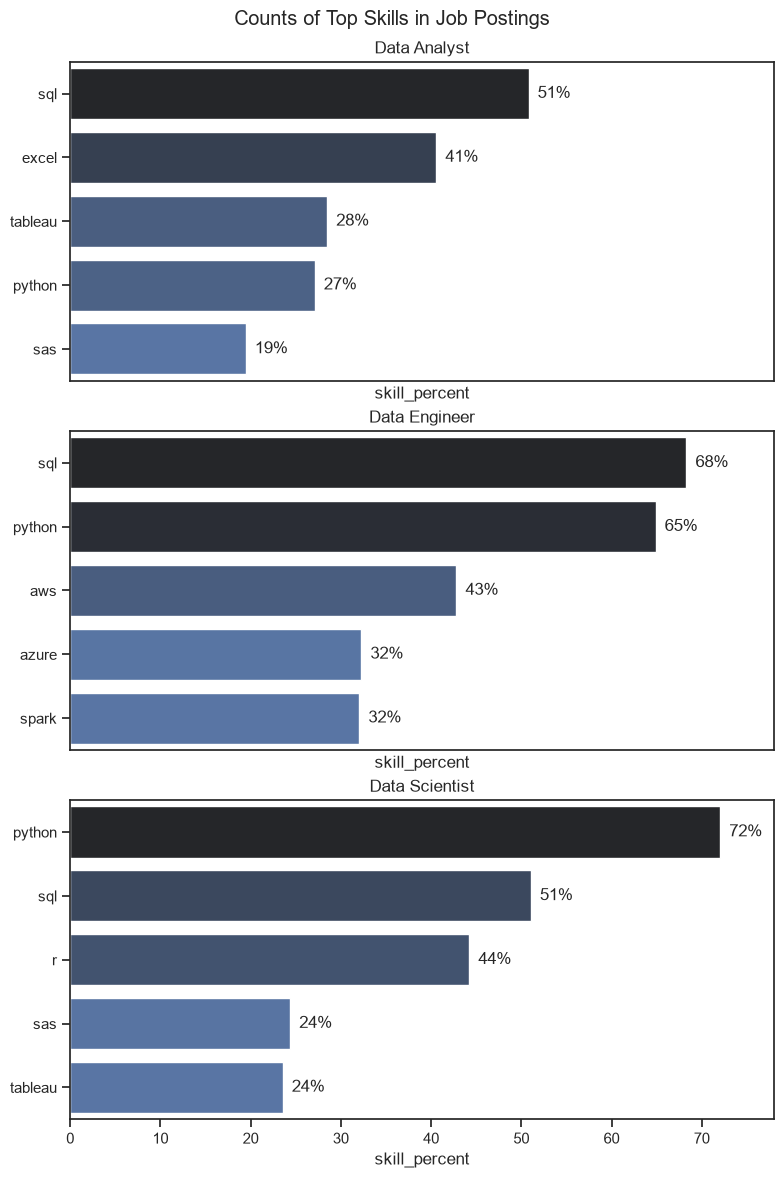

In [13]:
fig, ax = plt.subplots(len(job_titles), 1)
fig.set_size_inches(8, 12)

sns.set_theme(style='ticks')

for i, job_title in enumerate(job_titles):
    df_plot = df_skills_perc[df_skills_perc['job_title_short'] == job_title].head(5)

    sns.barplot(data=df_plot, x= 'skill_percent', y= 'job_skills', ax=ax[i], hue= 'skill_count', palette= 'dark:b_r')

    
    ax[i].set_title(job_title)
    ax[i].set_ylabel('')
    ax[i].legend().set_visible(False)
    ax[i].set_xlim(0, 78)

    for n, v in enumerate(df_plot['skill_percent']):
        ax[i].text(v + 1, n, f'{v:.0f}%', va= 'center')

#if i want to remove the number and leave on only the axis below

    if i != len(job_titles) - 1:
        ax[i].set_xticks([])

fig.suptitle('Counts of Top Skills in Job Postings')
fig.tight_layout(h_pad=0.5) #fix the overlap
plt.show()